In [1]:
import openmc
import numpy as np
import matplotlib.pyplot as plt

In [2]:
xs_library = '/home/jpontes/xs_libraries/endfb-viii.0-hdf5/cross_sections.xml'

## Materials

In [3]:
PuGa = openmc.Material(name = 'Gallium alloyed Plutonium')
PuGa.add_nuclide('Pu239', 0.91951, 'ao')
PuGa.add_nuclide('Pu240', 0.043465, 'ao')
PuGa.add_nuclide('Pu241', 0.0028975, 'ao')
PuGa.add_element('Ga', 0.034132, 'ao')
PuGa.set_density('g/cm3', 15.61)
PuGa.volume = 4/3*np.pi*6.3849**3
materials = openmc.Materials([PuGa])
materials.cross_sections = xs_library
materials.export_to_xml()

## Geometry

In [4]:
R = 6.3849

In [5]:
sphere = openmc.Sphere(r = R, boundary_type = 'vacuum')
assembly_cell = openmc.Cell(region = -sphere, fill = PuGa)
assembly_universe = openmc.Universe(cells=[assembly_cell])
assembly_geometry = openmc.Geometry(assembly_universe)
assembly_geometry.export_to_xml()

## Tallies

In [6]:
r_grid = np.linspace(0, R, 6)

In [7]:
spherical_mesh = openmc.SphericalMesh(r_grid)
flux_tally = openmc.Tally(1, name='flux_tally')
flux_tally.scores = ['flux']
flux_tally.filters = [openmc.MeshFilter(spherical_mesh)]

universe_tally = openmc.Tally(2, name='universe_tally')
universe_tally.scores = ['flux']
universe_tally.filters = [openmc.UniverseFilter(assembly_universe)]
tallies = openmc.Tallies([flux_tally, universe_tally])
tallies.export_to_xml()

## Settings

In [8]:
settings = openmc.Settings()

# Initial particle source:

angular_dist = openmc.stats.Isotropic()

energy_dist = openmc.stats.Watt()

spatial_dist = openmc.stats.Box(sphere.bounding_box('-')[0], sphere.bounding_box('-')[1])

origin = openmc.IndependentSource(space = spatial_dist, angle = angular_dist, energy = energy_dist, particle = 'neutron', constraints = {'fissionable': True})

settings.source = origin

# Simulation parameters:

# Shannon entropy mesh:

entropy_mesh = openmc.RegularMesh(name = 'Entropy Mesh')
entropy_mesh.lower_left = sphere.bounding_box('-')[0]
entropy_mesh.upper_right = sphere.bounding_box('-')[1]
entropy_mesh.dimension = [10, 10, 10]
settings.entropy_mesh = entropy_mesh

# Simulation parameters:

settings.run_mode = 'eigenvalue'

settings.batches = 200
settings.inactive = 20
settings.particles = 100000
settings.export_to_xml()

In [15]:
openmc.run()

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

## Results

In [16]:
sp = openmc.StatePoint('statepoint.200.h5', autolink=False)
keff = sp.keff
entropy = sp.entropy
tallies = sp.tallies
flux_tally = tallies[1]
sp.close()

In [17]:
print(keff)

0.99959+/-0.00015


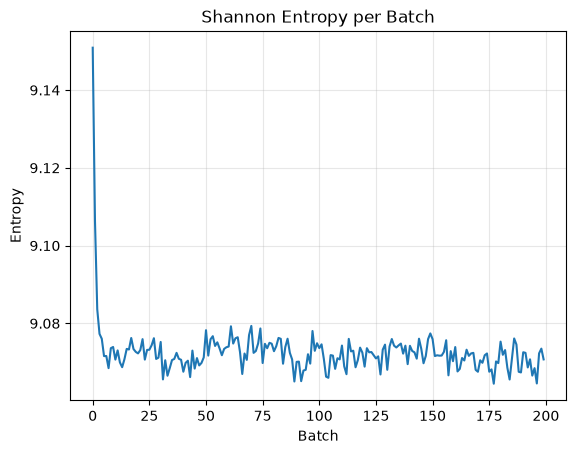

In [18]:
plt.plot(entropy)
plt.xlabel('Batch')
plt.ylabel('Entropy')
plt.title('Shannon Entropy per Batch')
plt.grid(alpha=0.3)
plt.show()

In [19]:
volumes = []
for i in range(1, len(r_grid)):
    volumes.append((4/3) * np.pi * (r_grid[i]**3 - r_grid[i-1]**3))

In [20]:
flux_tally.mean.ravel()

array([0.07004919, 0.45237572, 1.04231369, 1.54068212, 1.57953002])

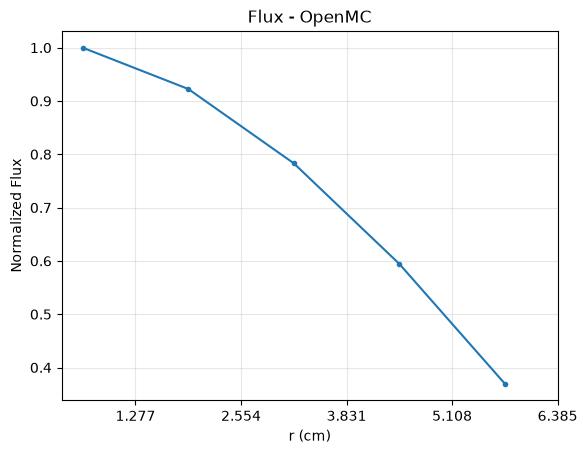

In [21]:
flux = flux_tally.mean.ravel() / volumes
r_mid = 0.5 * (r_grid[1:] + r_grid[:-1])   # shell midpoints instead of outer edges

plt.plot(r_mid, flux / flux.max(), '.-')
plt.xlabel('r (cm)')
plt.ylabel('Normalized Flux')
plt.xticks(np.linspace(0, R, 6)[1:])
plt.title('Flux - OpenMC')
plt.grid(alpha=0.3)
plt.show()